Running scheduling algorithms...

CLOUD TASK SCHEDULING RESULTS
Number of tasks       : 30
Number of virtual machines: 10
Number of particles   : 50
Number of iterations  : 200

Algorithm comparison (lower makespan is better):
Min-Min Makespan      : 15.569 seconds
Max-Min Makespan      : 13.578 seconds
Basic PSO Makespan    : 14.967 seconds
Dynamic PSO Makespan  : 14.949 seconds

Task Allocation using Dynamic PSO:
----------------------------------------
VM 01 | Tasks: None | Load: 0.000 seconds
VM 02 | Tasks: T15, T20 | Load: 13.963 seconds
VM 03 | Tasks: T6, T25 | Load: 14.559 seconds
VM 04 | Tasks: T14, T22 | Load: 12.312 seconds
VM 05 | Tasks: T1, T11, T24, T26 | Load: 14.709 seconds
VM 06 | Tasks: T8, T10, T30 | Load: 13.166 seconds
VM 07 | Tasks: T19, T23, T29 | Load: 12.414 seconds
VM 08 | Tasks: T2, T13, T16, T18 | Load: 13.032 seconds
VM 09 | Tasks: T7, T12, T17, T21, T27 | Load: 14.949 seconds
VM 10 | Tasks: T3, T4, T5, T9, T28 | Load: 14.031 seconds


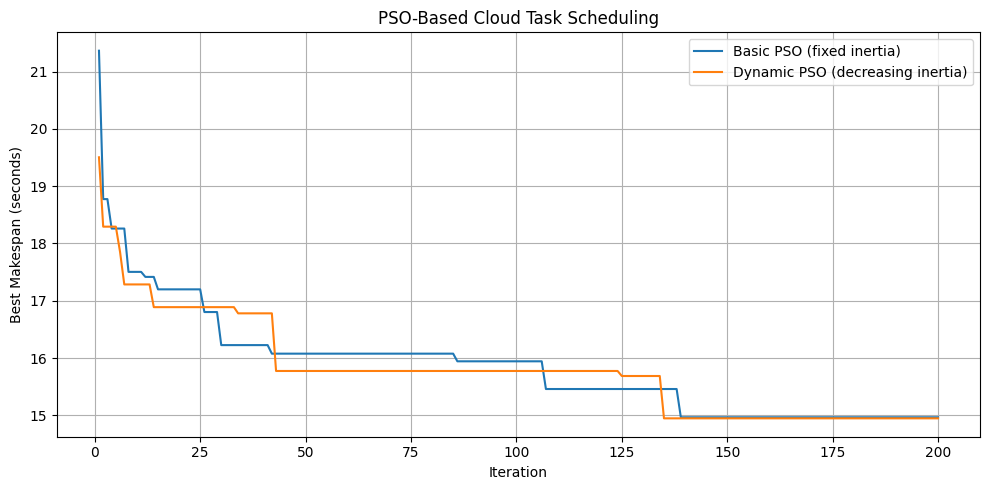

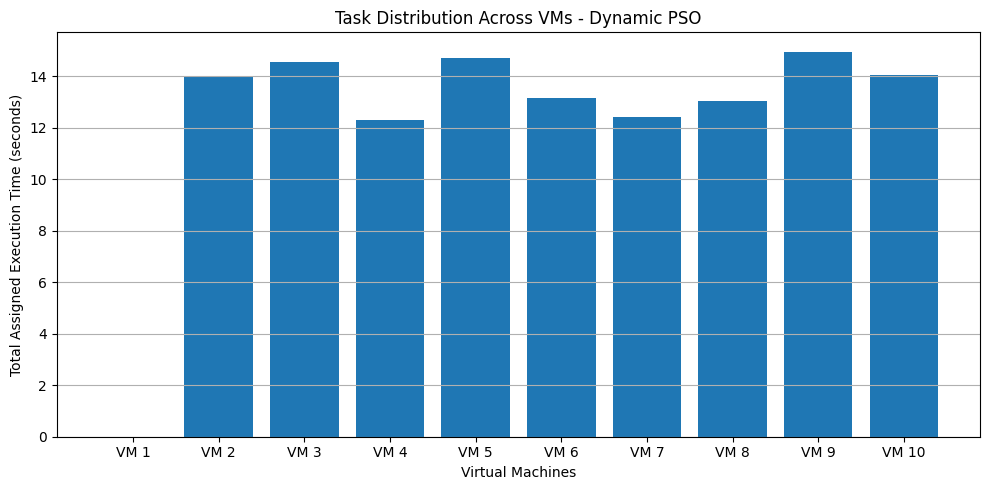

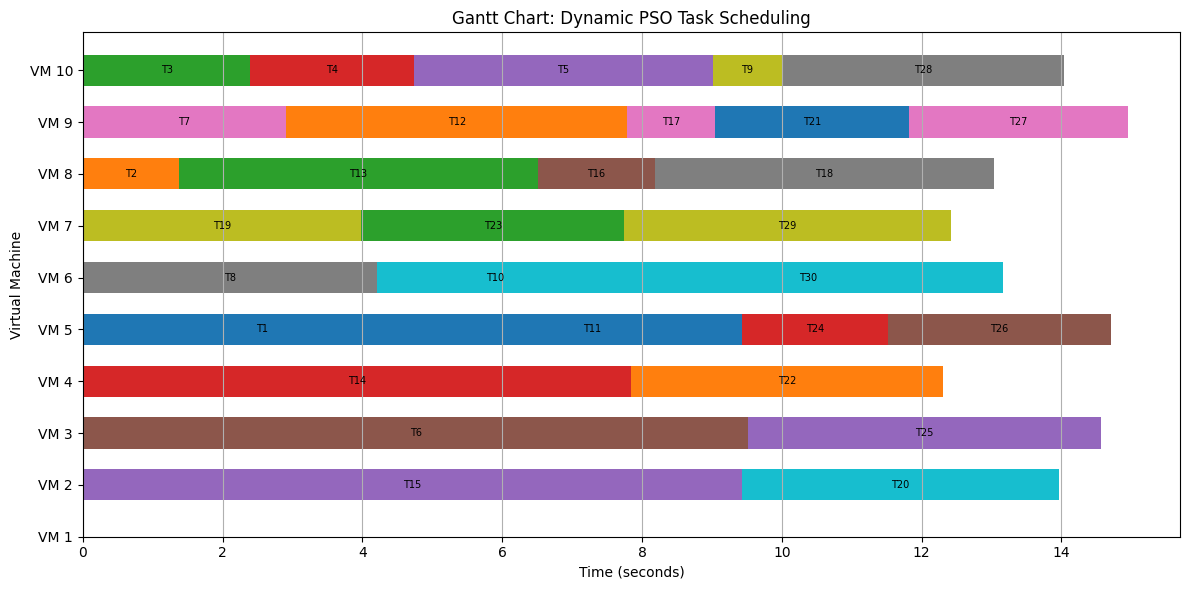


Simulation completed successfully!


In [ ]:

# ============================================================
# PSO-BASED CLOUD TASK SCHEDULING
# Inspired by the IEEE paper:
# "TSPSO: Enhanced Task Scheduling using Optimized Particle
# Swarm Algorithm in Cloud Computing Environment" (2023)
#
# Simplified Python simulation of dynamic-parameter PSO.
# This is NOT an exact reproduction of the paper's DAPDP.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ------------------------------------------------------------
# 1. CLOUD ENVIRONMENT
# ------------------------------------------------------------

NUM_TASKS = 30
NUM_VMS = 10

# Task lengths in Million Instructions (MI)
task_lengths = np.random.randint(
    3000, 15000, size=NUM_TASKS
)

# Processing capacity of each VM in Million Instructions/sec
vm_speeds = np.array([
    1000, 1200, 1500, 1800, 2000,
    2200, 2500, 2800, 3000, 3500
])

# Execution time of task i on VM j
# execution_times[i, j] = task length / VM speed
execution_times = (
    task_lengths[:, None] / vm_speeds[None, :]
)

# ------------------------------------------------------------
# 2. FITNESS FUNCTION
# ------------------------------------------------------------

def evaluate_schedule(assignments):
    """
    Calculate task execution times and makespan.
    assignments[i] specifies the VM assigned to task i.
    """
    vm_loads = np.zeros(NUM_VMS)

    for task_id, vm_id in enumerate(assignments):
        vm_loads[vm_id] += execution_times[task_id, vm_id]

    makespan = np.max(vm_loads)

    return makespan, vm_loads


# ------------------------------------------------------------
# 3. MIN-MIN SCHEDULING
# ------------------------------------------------------------

def min_min():
    vm_loads = np.zeros(NUM_VMS)
    assignments = np.full(NUM_TASKS, -1, dtype=int)
    unscheduled = set(range(NUM_TASKS))

    while unscheduled:
        best_task = None
        best_vm = None
        best_completion = float("inf")

        for task in unscheduled:
            for vm in range(NUM_VMS):
                completion = (
                    vm_loads[vm] + execution_times[task, vm]
                )

                if completion < best_completion:
                    best_completion = completion
                    best_task = task
                    best_vm = vm

        assignments[best_task] = best_vm
        vm_loads[best_vm] += execution_times[best_task, best_vm]
        unscheduled.remove(best_task)

    return evaluate_schedule(assignments)[0]


# ------------------------------------------------------------
# 4. MAX-MIN SCHEDULING
# ------------------------------------------------------------

def max_min():
    vm_loads = np.zeros(NUM_VMS)
    assignments = np.full(NUM_TASKS, -1, dtype=int)
    unscheduled = set(range(NUM_TASKS))

    while unscheduled:
        best_task = None
        best_vm = None
        largest_completion = -1

        for task in unscheduled:
            task_best_completion = float("inf")
            task_best_vm = None

            for vm in range(NUM_VMS):
                completion = (
                    vm_loads[vm] + execution_times[task, vm]
                )

                if completion < task_best_completion:
                    task_best_completion = completion
                    task_best_vm = vm

            if task_best_completion > largest_completion:
                largest_completion = task_best_completion
                best_task = task
                best_vm = task_best_vm

        assignments[best_task] = best_vm
        vm_loads[best_vm] += execution_times[best_task, best_vm]
        unscheduled.remove(best_task)

    return evaluate_schedule(assignments)[0]


# ------------------------------------------------------------
# 5. PARTICLE SWARM OPTIMIZATION
# ------------------------------------------------------------

def run_pso(dynamic_inertia=True):
    # Paper-inspired parameters
    NUM_PARTICLES = 50
    ITERATIONS = 200
    W_MAX = 0.8
    W_MIN = 0.4
    C1 = 2.0
    C2 = 2.0

    # Each particle has one position value per task.
    # Decode each position into a VM index.
    positions = np.random.uniform(
        0, NUM_VMS, (NUM_PARTICLES, NUM_TASKS)
    )

    velocities = np.random.uniform(
        -1, 1, (NUM_PARTICLES, NUM_TASKS)
    )

    def decode(position):
        return np.clip(
            np.floor(position).astype(int),
            0, NUM_VMS - 1
        )

    personal_best_positions = positions.copy()
    personal_best_scores = np.array([
        evaluate_schedule(decode(p))[0]
        for p in positions
    ])

    best_idx = np.argmin(personal_best_scores)
    global_best_position = personal_best_positions[best_idx].copy()
    global_best_score = personal_best_scores[best_idx]

    history = []

    for iteration in range(ITERATIONS):

        # Dynamic inertia: gradually decrease exploration
        if dynamic_inertia:
            w = W_MAX - (
                (W_MAX - W_MIN) * iteration / ITERATIONS
            )
        else:
            w = 0.7

        r1 = np.random.random((NUM_PARTICLES, NUM_TASKS))
        r2 = np.random.random((NUM_PARTICLES, NUM_TASKS))

        # Standard PSO velocity update
        velocities = (
            w * velocities
            + C1 * r1 * (
                personal_best_positions - positions
            )
            + C2 * r2 * (
                global_best_position - positions
            )
        )

        # Limit velocity to avoid excessive movement
        velocities = np.clip(velocities, -3, 3)

        # Update positions and keep them within valid bounds
        positions = positions + velocities
        positions = np.clip(
            positions, 0, NUM_VMS - 1e-9
        )

        # Evaluate new schedules
        for i in range(NUM_PARTICLES):
            assignment = decode(positions[i])
            score, _ = evaluate_schedule(assignment)

            # Update personal best
            if score < personal_best_scores[i]:
                personal_best_scores[i] = score
                personal_best_positions[i] = positions[i].copy()

            # Update global best
            if score < global_best_score:
                global_best_score = score
                global_best_position = positions[i].copy()

        history.append(global_best_score)

    best_assignment = decode(global_best_position)
    best_makespan, vm_loads = evaluate_schedule(best_assignment)

    return (
        best_assignment,
        best_makespan,
        vm_loads,
        history
    )


# ------------------------------------------------------------
# 6. RUN THE SCHEDULING ALGORITHMS
# ------------------------------------------------------------

print("Running scheduling algorithms...\n")

min_min_result = min_min()
max_min_result = max_min()

# Conventional PSO with fixed inertia weight
basic_assignment, basic_pso_result, _, basic_history = run_pso(
    dynamic_inertia=False
)

# Paper-inspired PSO with dynamically decreasing inertia
dapdp_assignment, dapdp_result, dapdp_vm_loads, dapdp_history = run_pso(
    dynamic_inertia=True
)

# ------------------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 60)
print("CLOUD TASK SCHEDULING RESULTS")
print("=" * 60)

print(f"Number of tasks       : {NUM_TASKS}")
print(f"Number of virtual machines: {NUM_VMS}")
print(f"Number of particles   : 50")
print(f"Number of iterations  : 200")

print("\nAlgorithm comparison (lower makespan is better):")
print(f"Min-Min Makespan      : {min_min_result:.3f} seconds")
print(f"Max-Min Makespan      : {max_min_result:.3f} seconds")
print(f"Basic PSO Makespan    : {basic_pso_result:.3f} seconds")
print(f"Dynamic PSO Makespan  : {dapdp_result:.3f} seconds")

# ------------------------------------------------------------
# 8. SHOW TASK ALLOCATION
# ------------------------------------------------------------

print("\nTask Allocation using Dynamic PSO:")
print("-" * 40)

for vm in range(NUM_VMS):
    tasks = [
        f"T{i + 1}"
        for i in range(NUM_TASKS)
        if dapdp_assignment[i] == vm
    ]

    print(
        f"VM {vm + 1:02d} | "
        f"Tasks: {', '.join(tasks) if tasks else 'None'} | "
        f"Load: {dapdp_vm_loads[vm]:.3f} seconds"
    )

# ------------------------------------------------------------
# 9. CONVERGENCE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(basic_history) + 1),
    basic_history,
    label="Basic PSO (fixed inertia)"
)

plt.plot(
    range(1, len(dapdp_history) + 1),
    dapdp_history,
    label="Dynamic PSO (decreasing inertia)"
)

plt.xlabel("Iteration")
plt.ylabel("Best Makespan (seconds)")
plt.title("PSO-Based Cloud Task Scheduling")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. VM LOAD BALANCING GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    [f"VM {i + 1}" for i in range(NUM_VMS)],
    dapdp_vm_loads
)

plt.xlabel("Virtual Machines")
plt.ylabel("Total Assigned Execution Time (seconds)")
plt.title("Task Distribution Across VMs - Dynamic PSO")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. TASK EXECUTION GANTT CHART
# ------------------------------------------------------------

vm_available = np.zeros(NUM_VMS)
task_start = np.zeros(NUM_TASKS)
task_end = np.zeros(NUM_TASKS)

for task_id, vm_id in enumerate(dapdp_assignment):
    start = vm_available[vm_id]
    duration = execution_times[task_id, vm_id]
    end = start + duration

    task_start[task_id] = start
    task_end[task_id] = end
    vm_available[vm_id] = end

fig, ax = plt.subplots(figsize=(12, 6))

for task_id, vm_id in enumerate(dapdp_assignment):
    ax.barh(
        vm_id,
        task_end[task_id] - task_start[task_id],
        left=task_start[task_id],
        height=0.6
    )

    ax.text(
        (task_start[task_id] + task_end[task_id]) / 2,
        vm_id,
        f"T{task_id + 1}",
        ha="center",
        va="center",
        fontsize=7
    )

ax.set_yticks(range(NUM_VMS))
ax.set_yticklabels([f"VM {i + 1}" for i in range(NUM_VMS)])
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Virtual Machine")
ax.set_title("Gantt Chart: Dynamic PSO Task Scheduling")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

print("\nSimulation completed successfully!")
